# Deep Learning
## Practical Deep Learning Tutorial with PyTorch - Tutorial N° 2

### 2025-2026

# Importing necessary libraries

In [16]:
import torch
import torch.nn as nn
from torch.autograd import grad
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs, make_moons

# Adaline

1. Build the ADALINE model using the `nn.Module` class. The model performs a linear transformation $\hat{y} = Xw^T + b$, with weights and bias initialised to zero.

In [17]:
class Adaline(torch.nn.Module):
    def __init__(self, num_features):
        super(Adaline, self).__init__()
        self.linear =  nn.Linear(num_features, 1) 
        with torch.no_grad():
            self.linear.weight.zero_() 
            self.linear.bias.zero_() 
    def forward(self, x):
        activations = self.linear(x)
        return activations.view(-1)

2. Using 'iris.txt', create a binary dataset in 2-D : the last 100 instances of iris described only by the 2nd and 3rd features.

    Split the dataset into training and test sets (70%, 30%).

    Normalize the dataset. **Why must the mean and standard deviation be computed on the training set only?**

In [18]:
df = pd.read_csv('iris.txt', index_col=None, header=None)
df.columns = ['x1', 'x2', 'x3', 'x4', 'y']
df = df.iloc[50:150]                         # last 100 instances (2 last classes)
df['y'] = df['y'].apply(lambda x: 0 if x == 'Iris-versicolor' else 1)

# Assign features and target
X = torch.tensor(df[['x2', 'x3']].values, dtype=torch.float)
y = torch.tensor(df['y'].values, dtype=torch.int)

# Shuffling & train/test split
torch.manual_seed(123)
shuffle_idx = torch.randperm(y.size(0), dtype=torch.long)
percent70 = int(shuffle_idx.size(0)*0.7)
X_train, X_test = X[shuffle_idx[:percent70]], X[shuffle_idx[percent70:]]
y_train, y_test = y[shuffle_idx[:percent70]], y[shuffle_idx[percent70:]]

# Normalize (mean zero, unit variance) : 
mu, sigma = X_train.mean(axis=0), X_train.std(axis=0)
X_train = (X_train - mu)/sigma
X_test = (X_test - mu)/sigma

mu_train, sigma_train = X_train.mean(), X_train.std()

print(f"Moyenne : {mu_train} & Sigma : {sigma_train}")


Moyenne : 2.8950827513085642e-08 & Sigma : 0.9963963627815247


In [19]:
model = Adaline(num_features=X_train.size(1))
model

Adaline(
  (linear): Linear(in_features=2, out_features=1, bias=True)
)

3. Train the model : we will use `MSELoss` (mean squared error) as loss function. The optimizer is SGD (Stochastic Gradient Descent) with learning rate 0.01.

    The function `train` must **return the list of the loss values at each epoch**. Plot this cost curve.

In [20]:
def train(model, x, y, num_epochs, learning_rate, seed):
    cost = []
    torch.manual_seed(seed)
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate) 
    loss = nn.MSELoss() 
    for e in range(num_epochs):
        y_pred = model(x)
        #y_pred = model.forward(x)
        
        loss_value = loss(y_pred,y)
        optimizer.zero_grad()

        loss_value.backward()

        optimizer.step()#IMPORTANT Sans ça on a une droite et non une courbe
        #Cette instruction permet de mettre à jour les paramètres du modèle après le calcul des gradients.

        cost.append(loss_value.item())
        #CONSIGNE : 
        # forward pass, loss, gradient reset, backward pass, update
        # store the loss of the epoch in cost
        pass
    return cost

[0.5285714268684387, 0.5104926228523254, 0.4932100474834442, 0.4766862690448761, 0.46088555455207825, 0.4457741677761078, 0.43131980299949646, 0.41749200224876404, 0.4042615592479706, 0.39160090684890747, 0.3794836401939392, 0.3678847849369049, 0.3567804992198944, 0.34614813327789307, 0.3359661102294922, 0.3262139856815338, 0.31687211990356445, 0.30792203545570374, 0.2993459403514862, 0.2911270260810852, 0.28324925899505615, 0.2756973206996918, 0.26845666766166687, 0.26151347160339355, 0.2548544704914093, 0.2484670877456665, 0.2423393577337265, 0.23645979166030884, 0.2308175265789032, 0.22540217638015747, 0.22020386159420013, 0.21521306037902832, 0.21042083203792572, 0.2058185338973999, 0.20139800012111664, 0.19715140759944916, 0.19307127594947815, 0.18915055692195892, 0.18538238108158112, 0.1817602664232254, 0.17827805876731873, 0.17492984235286713, 0.17170993983745575, 0.1686129868030548, 0.16563382744789124, 0.16276755928993225, 0.1600094586610794, 0.15735508501529694, 0.15480011701

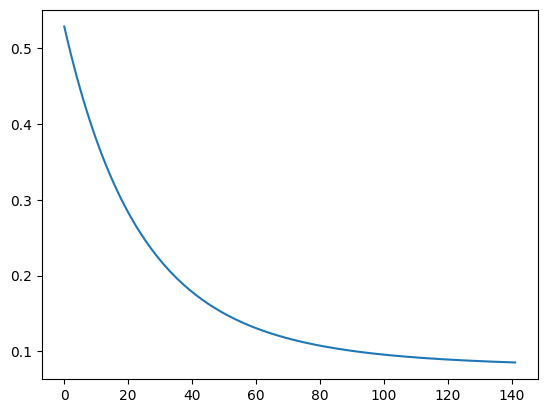

In [21]:
cost = train(model, X_train, y_train.float(), num_epochs=142, learning_rate=0.01, seed=123)
print(cost)
plt.plot(cost)
plt.show()

4. Compute the model accuracy

In [22]:
def custom_where(cond, x_1, x_2):
    return (cond * x_1) + (torch.logical_not(cond) * x_2)

train_pred = model.forward(X_train)
train_acc = torch.mean((custom_where(train_pred > 0.5, 1, 0).int() == y_train).float())
test_pred = model.forward(X_test)
test_acc = torch.mean((custom_where(test_pred > 0.5, 1, 0).int() == y_test).float())
print('Training Accuracy: %.2f' % (train_acc*100))
print('Test Accuracy: %.2f' % (test_acc*100))
print('Weights', model.linear.weight)
print('Bias', model.linear.bias)

Training Accuracy: 92.86
Test Accuracy: 90.00
Weights Parameter containing:
tensor([[-0.0336,  0.3843]], requires_grad=True)
Bias Parameter containing:
tensor([0.4986], requires_grad=True)


5. a. Plot the training points (one color per class) and the decision boundary of the Adaline. Give the equation of this boundary as a function of $w_1$, $w_2$ and $b$ (be careful: the threshold is 0.5, not 0).

   b. Train a new Adaline for each learning rate in {0.001, 0.01, 0.1, 0.5} and plot the 4 cost curves on the same figure. What happens for the largest value? Explain.

In [23]:
#...

# Perceptron

6. Build a Perceptron model **from scratch** (without autograd and without optimizer):
    - `forward` returns the predictions in {0, 1} (step function),
    - `backward` returns the errors $y - \hat{y}$,
    - `train` applies the perceptron learning rule example by example, and must **return the number of misclassified examples at each epoch**.

In [ ]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

class Perceptron():
    def __init__(self, num_features):
        self.num_features = num_features
        self.weights = torch.zeros(num_features, 1, dtype=torch.float32, device=device)
        self.bias = torch.zeros(1, dtype=torch.float32, device=device)
        self.ones = torch.ones(1, device=device)
        self.zeros = torch.zeros(1, device=device)

    def forward(self, x): #CHATGPT
        y  = torch.mm(x, self.weights) + self.bias
        prediction = torch.where(y > 0, self.ones, self.zeros)
        return prediction

    def backward(self, x, y):
        y_ = self.forward(x)
        errors = y  - y_
        return errors

    def train(self, x, y, epochs):
        n_errors = []
        for e in range(epochs):
            for i in range(y.shape[0]):
                errors = y[i] - self.forward(x[i].view(1, -1)) # transf vecteur en 1 ligne
                self.weights += errors * x[i].view(-1, 1) # tenseur en col
                self.bias += errors.view(-1) # transf en 1D
            prediction = self.forward(x)
            cpt = (prediction != y).sum().item()
            n_errors.append(cpt)
        return n_errors

    def evaluate(self, x, y):
        predictions = self.forward(x).reshape(-1)
        accuracy = torch.sum(predictions == y).float() / y.shape[0]
        return accuracy

7. Load the 'perceptron_toydata' dataset

    Split the dataset into train and test sets

    Normalize the data

In [25]:
df = pd.read_csv('perceptron_toydata.txt', index_col=None, header=None, delimiter='\t')
df.columns = ['x1', 'x2', 'y']
X = torch.tensor(df[['x1', 'x2']].values, dtype=torch.float)
y = torch.tensor(df['y'].values, dtype=torch.int)
print('Class label counts:', torch.bincount(y))
print('X.shape:', X.shape)
print('y.shape:', y.shape)

# Shuffling & train/test split
torch.manual_seed(123)
shuffle_idx = torch.randperm(y.size(0), dtype=torch.long)
percent70 = int(shuffle_idx.size(0)*0.7)
X_train, X_test = X[shuffle_idx[:percent70]], X[shuffle_idx[percent70:]]
y_train, y_test = y[shuffle_idx[:percent70]], y[shuffle_idx[percent70:]]

# Normalize (mean zero, unit variance)
mu, sigma = X_train.mean(axis=0), X_train.std(axis=0)
X_train = (X_train - mu) / sigma
X_test = (X_test - mu) / sigma

Class label counts: tensor([50, 50])
X.shape: torch.Size([100, 2])
y.shape: torch.Size([100])


8. Train the perceptron and plot the number of errors per epoch.

Model parameters:
  Weights: tensor([[-0.4330],
        [ 1.9000]])
  Bias: tensor([0.])


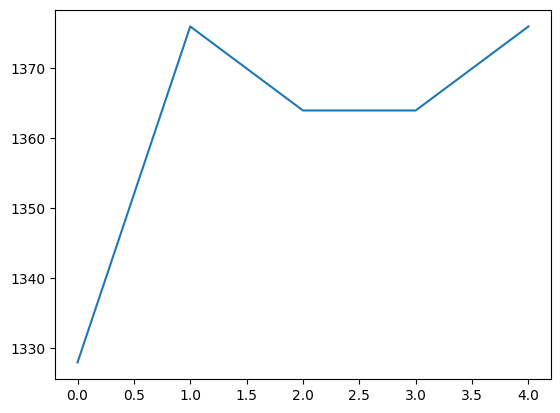

In [31]:
model = Perceptron(num_features=2)

X_train_tensor = X_train.clone().detach().to(device)
y_train_tensor = y_train.clone().detach().float().to(device)

n_errors = model.train(X_train_tensor, y_train_tensor, epochs=5)

print('Model parameters:')
print('  Weights: %s' % model.weights)
print('  Bias: %s' % model.bias)
# TODO : plot n_errors
plt.plot(n_errors)
plt.show()

9. Evaluate the model (accuracy)

In [27]:
X_test_tensor = X_test.clone().detach().to(device)
y_test_tensor = y_test.clone().detach().float().to(device)

test_acc = model.evaluate(X_test_tensor, y_test_tensor)
print('Test set accuracy: %.2f%%' % (test_acc*100))

Test set accuracy: 93.33%


10. a. Plot the test points and the decision boundary of the perceptron.

    b. Under which condition on the data is the perceptron learning rule guaranteed to converge? Train your perceptron for 20 epochs on the **iris dataset of the Adaline part** and plot the number of errors per epoch. What do you observe? Compare with the Adaline and explain.

# Multi Layer Perceptron

Unlike the single-layer perceptron, the Multi Layer Perceptron models have hidden layers
between the input and the output layers. After every hidden layer, an activation function
is applied to introduce non-linearity.

11. Build a simple Multi Layer Perceptron model with one hidden layer.
After the hidden layer, we will use ReLU as activation before the information is sent to the output layer.
As an output activation function, we will use Sigmoid.

In [32]:
class MultilayerPerceptron(torch.nn.Module):
    def __init__(self, num_features, num_hidden_1):
        super(MultilayerPerceptron, self).__init__()
        self.hidden_layer = torch.nn.Linear(num_features, num_hidden_1) # couche cachée
        self.output_layer = torch.nn.Linear(num_hidden_1, 1) # renvoie la décision finale (binaire donc juste 1 sortie)

    def forward(self, x):
        a = self.hidden_layer(x)
        b = torch.relu(a)
        c = self.output_layer(b)
        out = torch.sigmoid(c)
        return out

12. Create a random dataset and assign binary labels {0,1}

In [33]:
def blob_label(y, label, loc): # assign labels
    target = np.copy(y)
    for l in loc:
        target[y == l] = label
    return target

# make_blobs pour générer un jeu de données artificiel (créé nuage de points)
# précision : par défaut 3 clusters sinon il faudrait ajouter param centers or pas le cas ici donc là notre 4eme cluster est vide donc inutile
x_train, y_train = make_blobs(n_samples=40, n_features=2, cluster_std=1.5, shuffle=True, random_state=0)
x_train = torch.FloatTensor(x_train)
y_train = torch.FloatTensor(blob_label(y_train, 0, [0]))
y_train = torch.FloatTensor(blob_label(y_train, 1, [1,2,3]))
x_test, y_test = make_blobs(n_samples=10, n_features=2, cluster_std=1.5, shuffle=True, random_state=1)
x_test = torch.FloatTensor(x_test)
y_test = torch.FloatTensor(blob_label(y_test, 0, [0]))
y_test = torch.FloatTensor(blob_label(y_test, 1, [1,2,3]))
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

torch.Size([40, 2])
torch.Size([40])
torch.Size([10, 2])
torch.Size([10])


13. Define the model with input dimension 2 and hidden dimension 10.
Since the task is to classify binary labels, we can use as criterion BCELoss (Binary Cross Entropy Loss).
The optimizer is SGD (Stochastic Gradient Descent) with learning rate 0.01.

In [34]:
model = MultilayerPerceptron(2, 10)
criterion = nn.BCELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

14. Check the test loss before the model training and compare it with the test loss after the training.

In [35]:
model.eval()
y_pred = model(x_test)
before_train = criterion(y_pred.squeeze(), y_test)
print('Test loss before training' , before_train.item())

Test loss before training 0.6911336183547974


In [40]:
model.train()
epoch = 20
for epoch in range(epoch):
    optimizer.zero_grad()
    y_pred = model(x_train)
    loss = criterion(y_pred.view(-1), y_train) # pb de dim donc view nécessaire
    print('Epoch {}: train loss: {}'.format(epoch, loss.item()))
    # Backward pass
    loss.backward()
    optimizer.step()

Epoch 0: train loss: 0.6432976126670837
Epoch 1: train loss: 0.6420162916183472
Epoch 2: train loss: 0.6407502889633179
Epoch 3: train loss: 0.639496386051178
Epoch 4: train loss: 0.6382585763931274
Epoch 5: train loss: 0.6370362639427185
Epoch 6: train loss: 0.6358288526535034
Epoch 7: train loss: 0.6346356868743896
Epoch 8: train loss: 0.6334561109542847
Epoch 9: train loss: 0.6322898268699646
Epoch 10: train loss: 0.6311362385749817
Epoch 11: train loss: 0.6299948692321777
Epoch 12: train loss: 0.6288653612136841
Epoch 13: train loss: 0.6277472376823425
Epoch 14: train loss: 0.6266401410102844
Epoch 15: train loss: 0.6255437731742859
Epoch 16: train loss: 0.6244578957557678
Epoch 17: train loss: 0.6233819723129272
Epoch 18: train loss: 0.6223160028457642
Epoch 19: train loss: 0.6212593913078308


In [41]:
model.eval()
y_pred = model(x_test)
after_train = criterion(y_pred.squeeze(), y_test)
print('Test loss after Training' , after_train.item())

Test loss after Training 0.5902127623558044


15. Write a function `accuracy(model, x, y)`. Re-initialise the model and train it for 500 epochs, recording at each epoch the train loss, the test loss and the test accuracy. Plot the two loss curves on the same figure and comment (under-fitting / over-fitting?).

Test loss after Training 0.7419205904006958
Test loss after Training 0.7324553728103638
Test loss after Training 0.7233762145042419
Test loss after Training 0.7146287560462952
Test loss after Training 0.7062191963195801
Test loss after Training 0.6980514526367188
Test loss after Training 0.6902223229408264
Test loss after Training 0.6827174425125122
Test loss after Training 0.6755224466323853
Test loss after Training 0.6686237454414368
Test loss after Training 0.6620084643363953
Test loss after Training 0.6556639671325684
Test loss after Training 0.6495787501335144
Test loss after Training 0.6437407732009888
Test loss after Training 0.6381390690803528
Test loss after Training 0.6327688694000244
Test loss after Training 0.6276134252548218
Test loss after Training 0.622663140296936
Test loss after Training 0.6179088354110718
Test loss after Training 0.6133416295051575
Test loss after Training 0.6089480519294739
Test loss after Training 0.6047250628471375
Test loss after Training 0.600665

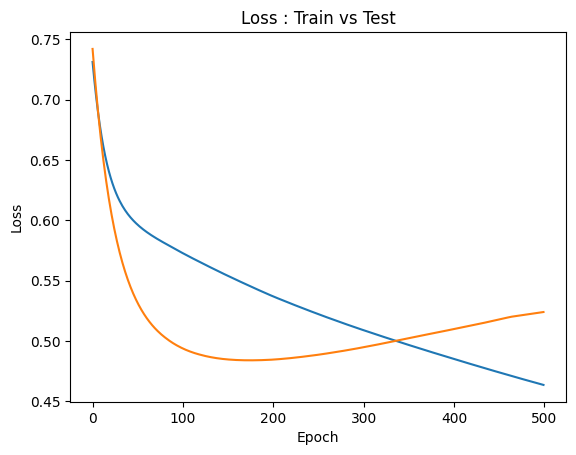

In [46]:
def accuracy(model, x, y):
    acc = ((model(x).view(-1) >= 0.5).float() == y).float().mean()
    return acc.item()

model = MultilayerPerceptron(2, 10)
criterion = nn.BCELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

train_loss = []
test_loss = []
test_accuracy = []

for epoch in range(500) :
    model.train()
    optimizer.zero_grad()
    y_pred = model(x_train)
    loss = criterion(y_pred.view(-1), y_train) # pb de dim donc view nécessaire
    loss.backward()
    optimizer.step()

    model.eval()
    y_pred = model(x_test)
    after_train = criterion(y_pred.squeeze(), y_test)
    print('Test loss after Training' , after_train.item())

    train_loss.append(loss.item())
    test_loss.append(after_train.item())

    acc_test = accuracy(model, x_test, y_test)
    test_accuracy.append(acc_test)

plt.figure()
plt.plot(train_loss, label="Train Loss")
plt.plot(test_loss, label="Test Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss : Train vs Test")
plt.show()

16. Non linearly separable data. Generate a dataset with `make_moons(n_samples=300, noise=0.2, random_state=0)` (train/test split 70/30).

    a. Train a single-layer model (`nn.Linear(2, 1)` followed by a Sigmoid, BCE loss) and your MLP.

    b. For each model, plot the decision regions (hint: evaluate the model on a grid built with `np.meshgrid`, then use `plt.contourf`) and give the test accuracy.

    c. Conclude: what does the hidden layer bring?

Text(0.5, 1.0, 'Modèle MLP')

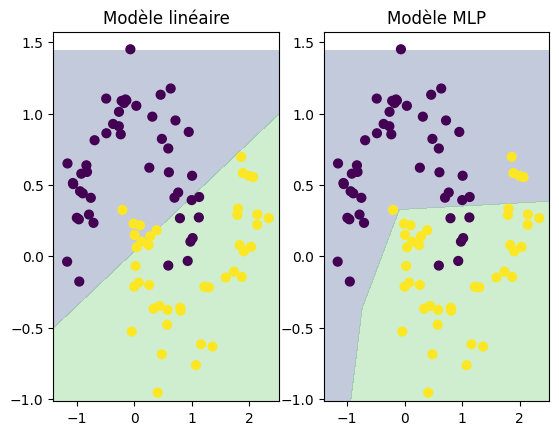

In [60]:
x,y = make_moons(n_samples=300, noise=0.2, random_state=0)
X = torch.tensor(x, dtype=torch.float32)
Y = torch.tensor(y, dtype=torch.float32)

torch.manual_seed(123)
shuffle_idx = torch.randperm(Y.size(0), dtype=torch.long)
percent70 = int(shuffle_idx.size(0)*0.7)
X_train, X_test = X[shuffle_idx[:percent70]], X[shuffle_idx[percent70:]]
y_train, y_test = Y[shuffle_idx[:percent70]], Y[shuffle_idx[percent70:]]

linear = nn.Sequential(nn.Linear(2, 1), nn.Sigmoid())
criterion = nn.BCELoss()

model = MultilayerPerceptron(2, 10)

optimizer_linear = torch.optim.SGD(linear.parameters(), lr=0.1)
optimizer_model = torch.optim.SGD(model.parameters(), lr=0.2)

for epoch in range(500):
        linear.train()
        optimizer_linear.zero_grad()
        y_pred = linear(X_train).view(-1)
        loss = criterion(y_pred, y_train)
        loss.backward()
        optimizer_linear.step()


for epoch in range(1500):
        model.train()
        optimizer_model.zero_grad()
        y_pred = model(X_train).view(-1)
        loss = criterion(y_pred, y_train)
        loss.backward()
        optimizer_model.step()

accuracy(model, X_test, y_test)
accuracy(linear, X_test, y_test)

x_meshgrid, y_meshgrid = np.meshgrid( # génère suite régulière de nombres
    np.arange(X[:, 0].min(), X[:, 0].max(), 0.02),
    np.arange(X[:, 1].min(), X[:, 1].max(), 0.02)
)

grid = torch.tensor(np.c_[x_meshgrid.ravel(), y_meshgrid.ravel()], dtype=torch.float32)

with torch.no_grad():
    Z_linear = linear(grid).reshape(x_meshgrid.shape).numpy()
    Z_model = model(grid).reshape(x_meshgrid.shape).numpy()

fig, ax = plt.subplots(1, 2)
ax[0].contourf(x_meshgrid, y_meshgrid, Z_linear, levels=[0, 0.5, 1], alpha=0.3)
ax[0].scatter(X_test[:, 0],X_test[:, 1],c=y_test,s=40)
ax[0].set_title(f"Modèle linéaire")

ax[1].contourf(x_meshgrid, y_meshgrid, Z_model, levels=[0, 0.5, 1], alpha=0.3)
ax[1].scatter(X_test[:, 0],X_test[:, 1],c=y_test,s=40)
ax[1].set_title(f"Modèle MLP")

# on a augmenté le nombre d'epoch et le learning rate pour avoir une frontière + courbée

17. In order to improve the model, you can try out different values for your
hyperparameters (hidden dimension size, number of epochs, learning rate). You can also
try changing the structure of your model (adding more hidden layers). Summarize your experiments in a table (configuration, test accuracy) and justify your best choice.

In [66]:
model1 = nn.Sequential(nn.ReLU(), nn.Sigmoid())
optimizer1 = torch.optim.SGD(model1.parameters(), lr=0.01)

for epoch in range(500):
    model1.train()
    optimizer1.zero_grad()
    loss = criterion(model1(X_train).view(-1), y_train)
    loss.backward()
    optimizer1.step()

model1.eval()
with torch.no_grad():
    accuracy(model1, X_test, y_test)
    Z1 = model1(grid).reshape(x_meshgrid.shape).numpy()

print(f"Config 1 (10 neurones, lr=0.01, 500 époques)")

plt.figure()
plt.contourf(x_meshgrid, y_meshgrid, Z1, levels=[0, 0.5, 1], alpha=0.3)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, s=40)
plt.title(f"Config 1 (10 neurones, lr=0.01, 500 époques)")
plt.show()

ValueError: optimizer got an empty parameter list